# Classical ML analysis notebook for tiered neutron-signature datasets

This notebook is a refactor of the original `final_project.ipynb` for your tiered `ml_datasets` directory.

Main goals:

- use **relative paths** and **auto-discovery** instead of machine-specific absolute paths
- make **feature selection explicit** instead of relying on `iloc[:, 8:]`
- keep **source_case-separated** workflows by default
- reduce repeated code by moving clustering / supervised evaluation into reusable functions
- add **better plots**, **cross-validation summaries**, **confusion matrices**, **top-feature tables**, and **optional hyperparameter search**
- make it easier to compare **Tier 0 -> Tier 5/6** datasets from the same directory


## Review of the original notebook

### What was already good
- It got from CSV to first-pass models quickly.
- It explored both **unsupervised** and **supervised** learning.
- It kept track of both **`class_label`** and **`snmMaterial`**.
- It was useful as a first proof-of-concept that the datasets are model-ready.

### Main issues that were worth fixing
1. **Hard-coded Windows paths**  
   The original notebook loaded CSVs from `C:\Users\...\Downloads\...`, which will break as soon as the notebook moves to the shared `ml_datasets` folder.

2. **Feature selection by column index**  
   The original code used `data_95.iloc[:, 8:]`. That is brittle. If the CSV schema changes, the notebook may silently train on the wrong columns.

3. **Scaled features were created but not actually used for clustering**  
   `X_scaled` was computed, but clustering was still fit on raw `X`.

4. **Unsupervised accuracy was not permutation-safe**  
   Raw `accuracy_score(true_labels, cluster_labels)` is misleading for clustering because cluster labels are arbitrary. This notebook uses **AMI / ARI / NMI** and also a **Hungarian-matched cluster accuracy** for an intuitive check.

5. **Repeated code blocks**  
   KMeans, GMM, supervised fits, and feature-importance plotting were repeated in slightly different forms. That makes it harder to maintain and compare results.

6. **Unused / unrelated imports**  
   The original notebook imported Gaussian processes, regressors, and error metrics that were not actually used in the classification workflow.

7. **One broken cell**  
   The GMM line `GaussianMixture(n_components=3, random_state=)` is a syntax error.

8. **Limited reporting**  
   The original notebook printed a few accuracies, but did not summarize CV means/stds, confusion matrices, or top features cleanly.

### Philosophy of this refactor
This version stays simple and classical, but it is much safer for repeated analysis across many tiered datasets.


In [27]:

from pathlib import Path
import fnmatch
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

from scipy.optimize import linear_sum_assignment

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.metrics import (
    adjusted_mutual_info_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.figsize"] = (8, 5)


In [28]:
# -----------------------------
# User configuration
# -----------------------------
DATA_DIR = Path(".").resolve()

# Pick one dataset for detailed analysis.
# Keep this within a single source_case unless you intentionally want to test
# robustness to source-case mismatch.
ACTIVE_DATASET = "tier5b_lowgt60_1e2_sc50.csv"

# Pattern used for quick comparison across multiple datasets.
# Staying within one source_case is strongly recommended.
COMPARE_GLOB = "tier*_sc50.csv"

ALLOW_DEBUG_DATASETS = False
INCLUDE_MEASUREMENT_SETTINGS_AS_FEATURES = False
DROP_CONSTANT_FEATURES = True

# Feature-set control:
#   "all_observable"       -> current default behavior
#   "no_energy"            -> keep everything except explicit energy-derived features
#   "counts_clusters_only" -> keep only count_total + coincidence/cluster features
#   "counts_only"          -> keep only count_total
#   "clusters_only"        -> keep only n_clusters/max_cluster/mean_cluster/n_clusters_ge*
#   "energy_only"          -> keep only energy-derived observables
#   "custom"               -> use CUSTOM_INCLUDE_FEATURES exactly
FEATURE_VIEW = "counts_clusters_only"

# Used only if FEATURE_VIEW == "custom"
CUSTOM_INCLUDE_FEATURES = [
    # "count_total",
    # "n_clusters",
    # "max_cluster",
    # "mean_cluster",
    # "n_clusters_ge2",
    # "n_clusters_ge3",
    # "n_clusters_ge4",
    # "n_clusters_ge10",
]

# Optional extra regex exclusions applied after FEATURE_VIEW selection.
CUSTOM_EXCLUDE_PATTERNS = []

PRINT_SELECTED_FEATURES = True

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
TOP_N_FEATURES = 15

RUN_HYPERPARAMETER_SEARCH = False
N_RANDOM_SEARCH_ITERS = 20
TUNING_TARGET = "class_label"   # "class_label" or "snmMaterial"
TUNING_MODEL = "RandomForest"   # "RandomForest", "LogisticRegression", or "GradientBoosting"


In [29]:
LABEL_COLUMNS = ["class_label", "snmMaterial"]
DEFAULT_METADATA_COLUMNS = ["sample_index", "source_case", "flux_regime"]
MEASUREMENT_SETTING_COLUMNS = ["window_s", "coinc_ns", "background_rate_hz"]

DEBUG_OR_PROVENANCE_PATTERNS = [
    r"^material_exact$",
    r"^scenario_id$",
    r"^split_group_id$",
    r"^geant_seed_ids$",
    r"^ml_split$",
    r"^qc_",
    r"^flux_regime_",
    r"^source_total_flux",
    r"^source_flux_",
    r"^sphere",
    r"^beam",
    r"^panel_",
    r"^physics",
    r"^projected_",
    r"^library_",
    r"^sampled_protons",
    r"^sampled_incident",
    r"^truth_",
    r"^signal_",
    r"^background_",
]

# -----------------------------
# Feature-family selectors
# -----------------------------
COUNT_ONLY_PATTERNS = [
    r"^count_total$",
]

CLUSTER_PATTERNS = [
    r"^n_clusters$",
    r"^max_cluster$",
    r"^mean_cluster$",
    r"^n_clusters_ge\d+$",
]

ENERGY_PATTERNS = [
    r"^count_gt\d+$",
    r"^frac_gt\d+$",
    r"^ratio_gt",
    r"^count_meanE_MeV$",
    r"^count_medianE_MeV$",
    r"^count_energy_hist_",
    r"^frac_energy_hist_covered$",
    r"^Ebin_",
]

def parse_dataset_filename(name: str) -> dict:
    stem = Path(name).stem
    tier_match = re.search(r"^(tier\d+[a-z]?)", stem)
    source_case_match = re.search(r"_sc(\d+)", stem)
    return {
        "name": name,
        "stem": stem,
        "tier": tier_match.group(1) if tier_match else None,
        "source_case": int(source_case_match.group(1)) if source_case_match else None,
        "is_debug": stem.endswith("_debug"),
        "is_summary": stem.endswith("_library_summary"),
    }

def discover_dataset_files(data_dir: Path, allow_debug: bool = False) -> pd.DataFrame:
    records = []
    for path in sorted(data_dir.glob("*.csv")):
        if not path.name.startswith("tier"):
            continue
        meta = parse_dataset_filename(path.name)
        if meta["is_summary"]:
            continue
        if (not allow_debug) and meta["is_debug"]:
            continue
        meta["path"] = path
        meta["size_kb"] = path.stat().st_size / 1024.0
        records.append(meta)
    df = pd.DataFrame(records)
    if df.empty:
        return df
    return df.sort_values(["tier", "source_case", "name"]).reset_index(drop=True)

def choose_active_dataset(available_df: pd.DataFrame, active_name: str | None) -> Path:
    if available_df.empty:
        raise FileNotFoundError(
            f"No dataset CSVs were found in {DATA_DIR}. "
            "This notebook expects to live in the same directory as the tier*.csv files."
        )

    if active_name is None:
        return available_df.iloc[0]["path"]

    candidate = DATA_DIR / active_name
    if candidate.exists():
        return candidate

    raise FileNotFoundError(
        f"ACTIVE_DATASET='{active_name}' was not found in {DATA_DIR}.\n"
        f"Available datasets:\n  - " + "\n  - ".join(available_df['name'].tolist()[:50])
    )

def infer_feature_columns(
    df: pd.DataFrame,
    include_measurement_settings: bool = False,
    drop_constant_features: bool = True,
) -> tuple[list[str], dict]:
    drop_reasons = {
        "label_columns": [],
        "metadata_columns": [],
        "debug_or_provenance_columns": [],
        "non_numeric_columns": [],
        "constant_columns": [],
    }

    base_drop = set(LABEL_COLUMNS + DEFAULT_METADATA_COLUMNS)
    if not include_measurement_settings:
        base_drop.update(MEASUREMENT_SETTING_COLUMNS)

    for col in df.columns:
        if col in LABEL_COLUMNS:
            drop_reasons["label_columns"].append(col)
        elif col in base_drop:
            drop_reasons["metadata_columns"].append(col)
        elif any(re.search(pattern, col, flags=re.IGNORECASE) for pattern in DEBUG_OR_PROVENANCE_PATTERNS):
            drop_reasons["debug_or_provenance_columns"].append(col)
        elif not pd.api.types.is_numeric_dtype(df[col]):
            drop_reasons["non_numeric_columns"].append(col)

    dropped = set(
        drop_reasons["label_columns"]
        + drop_reasons["metadata_columns"]
        + drop_reasons["debug_or_provenance_columns"]
        + drop_reasons["non_numeric_columns"]
    )

    feature_cols = [c for c in df.columns if c not in dropped]

    if drop_constant_features:
        constant_cols = [c for c in feature_cols if df[c].nunique(dropna=False) <= 1]
        feature_cols = [c for c in feature_cols if c not in constant_cols]
        drop_reasons["constant_columns"] = constant_cols

    return feature_cols, drop_reasons

def prepare_feature_matrix(df: pd.DataFrame, feature_cols: list[str]) -> pd.DataFrame:
    X = df[feature_cols].copy()
    X = X.apply(pd.to_numeric, errors="coerce")
    X = X.replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return X

def make_joint_stratify_key(df: pd.DataFrame, targets: list[str]) -> pd.Series:
    return df[targets].astype(str).agg(" | ".join, axis=1)

def column_matches_any_pattern(col: str, patterns: list[str]) -> bool:
    return any(re.search(pat, col, flags=re.IGNORECASE) for pat in patterns)

def summarize_feature_families(feature_cols: list[str]) -> dict:
    return {
        "count_total": [c for c in feature_cols if column_matches_any_pattern(c, COUNT_ONLY_PATTERNS)],
        "cluster": [c for c in feature_cols if column_matches_any_pattern(c, CLUSTER_PATTERNS)],
        "energy": [c for c in feature_cols if column_matches_any_pattern(c, ENERGY_PATTERNS)],
    }

def apply_feature_view(
    feature_cols: list[str],
    feature_view: str = "all_observable",
    custom_include_features: list[str] | None = None,
    custom_exclude_patterns: list[str] | None = None,
) -> tuple[list[str], dict]:
    feature_view = str(feature_view).strip().lower()
    cols = list(feature_cols)

    if feature_view == "all_observable":
        selected = cols
    elif feature_view == "no_energy":
        selected = [c for c in cols if not column_matches_any_pattern(c, ENERGY_PATTERNS)]
    elif feature_view == "counts_clusters_only":
        selected = [
            c for c in cols
            if column_matches_any_pattern(c, COUNT_ONLY_PATTERNS + CLUSTER_PATTERNS)
        ]
    elif feature_view == "counts_only":
        selected = [c for c in cols if column_matches_any_pattern(c, COUNT_ONLY_PATTERNS)]
    elif feature_view == "clusters_only":
        selected = [c for c in cols if column_matches_any_pattern(c, CLUSTER_PATTERNS)]
    elif feature_view == "energy_only":
        selected = [c for c in cols if column_matches_any_pattern(c, ENERGY_PATTERNS)]
    elif feature_view == "custom":
        custom_include_features = custom_include_features or []
        selected = [c for c in cols if c in set(custom_include_features)]
    else:
        raise ValueError(
            f"Unsupported FEATURE_VIEW={feature_view!r}. "
            "Use one of: all_observable, no_energy, counts_clusters_only, "
            "counts_only, clusters_only, energy_only, custom."
        )

    if custom_exclude_patterns:
        selected = [
            c for c in selected
            if not column_matches_any_pattern(c, custom_exclude_patterns)
        ]

    selected = [c for c in selected if c in cols]
    if not selected:
        raise ValueError(
            "FEATURE_VIEW filtering removed every model feature. "
            "Choose a broader feature view or update CUSTOM_INCLUDE_FEATURES."
        )

    feature_family_summary = summarize_feature_families(selected)
    feature_view_info = {
        "feature_view": feature_view,
        "n_selected": len(selected),
        "n_count_total_features": len(feature_family_summary["count_total"]),
        "n_cluster_features": len(feature_family_summary["cluster"]),
        "n_energy_features": len(feature_family_summary["energy"]),
        "selected_features": selected,
    }
    return selected, feature_view_info


In [30]:
def encode_labels(y: pd.Series | np.ndarray) -> tuple[np.ndarray, LabelEncoder]:
    encoder = LabelEncoder()
    encoded = encoder.fit_transform(np.asarray(y))
    return encoded, encoder

def cluster_accuracy_hungarian(y_true, y_pred) -> float:
    yt, _ = encode_labels(y_true)
    yp, _ = encode_labels(y_pred)

    n = max(yt.max(), yp.max()) + 1
    contingency = np.zeros((n, n), dtype=int)
    for pred_label, true_label in zip(yp, yt):
        contingency[pred_label, true_label] += 1

    row_ind, col_ind = linear_sum_assignment(contingency.max() - contingency)
    return contingency[row_ind, col_ind].sum() / contingency.sum()

def tier_sort_key(name: str) -> tuple:
    tier_match = re.search(r"^tier(\d+)([a-z]?)", name)
    if tier_match:
        tier_num = int(tier_match.group(1))
        tier_suffix = tier_match.group(2) or ""
    else:
        tier_num = 999
        tier_suffix = ""
    source_case_match = re.search(r"_sc(\d+)", name)
    source_case = int(source_case_match.group(1)) if source_case_match else 999
    return (tier_num, tier_suffix, source_case, name)

def plot_label_counts(df: pd.DataFrame) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    class_counts = df["class_label"].value_counts().sort_index()
    material_counts = df["snmMaterial"].value_counts().sort_index()

    axes[0].bar(class_counts.index.astype(str), class_counts.values)
    axes[0].set_title("Rows by class_label")
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=30)

    axes[1].bar(material_counts.index.astype(str), material_counts.values)
    axes[1].set_title("Rows by snmMaterial")
    axes[1].tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

def project_features_to_2d(X: pd.DataFrame) -> tuple[np.ndarray, str]:
    X_scaled = StandardScaler().fit_transform(X)
    if X_scaled.shape[1] >= 2:
        pcs = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_scaled)
        axis_label = "PC"
    else:
        pcs = np.column_stack([X_scaled[:, 0], np.zeros(X_scaled.shape[0])])
        axis_label = "single_feature"
    return pcs, axis_label

def plot_pca_projection(X: pd.DataFrame, labels, title: str) -> None:
    labels = pd.Series(labels).astype(str)
    pcs, axis_label = project_features_to_2d(X)
    codes = pd.Categorical(labels).codes

    plt.figure(figsize=(7, 6))
    scatter = plt.scatter(pcs[:, 0], pcs[:, 1], c=codes, s=15, alpha=0.7)
    plt.xlabel("PC1" if axis_label == "PC" else "Feature 1 (standardized)")
    plt.ylabel("PC2" if axis_label == "PC" else "Zero-padded axis")
    plt.title(title)
    legend_labels = list(pd.Categorical(labels).categories)
    handles = scatter.legend_elements()[0]
    plt.legend(handles, legend_labels, title="Label", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

def plot_total_count_by_label(df: pd.DataFrame, label_col: str) -> None:
    if "count_total" not in df.columns:
        return

    labels = sorted(df[label_col].astype(str).unique())
    plt.figure(figsize=(8, 5))
    for label in labels:
        values = df.loc[df[label_col].astype(str) == label, "count_total"].values
        plt.hist(values, bins=30, alpha=0.5, label=label)
    plt.xlabel("count_total")
    plt.ylabel("Rows")
    plt.title(f"count_total distribution by {label_col}")
    plt.legend()
    plt.tight_layout()
    plt.show()

def run_clustering_suite(
    X: pd.DataFrame,
    y_true,
    random_state: int = 42,
) -> tuple[pd.DataFrame, dict]:
    X_scaled = StandardScaler().fit_transform(X)
    n_clusters = pd.Series(y_true).nunique()

    models = {
        "KMeans": KMeans(n_clusters=n_clusters, n_init=30, random_state=random_state),
        "Agglomerative": AgglomerativeClustering(n_clusters=n_clusters),
        "GaussianMixture": GaussianMixture(n_components=n_clusters, covariance_type="full", random_state=random_state),
    }

    rows = []
    fitted_labels = {}
    for model_name, model in models.items():
        try:
            cluster_labels = model.fit_predict(X_scaled)
            row = {
                "model": model_name,
                "n_clusters": n_clusters,
                "AMI": adjusted_mutual_info_score(y_true, cluster_labels),
                "ARI": adjusted_rand_score(y_true, cluster_labels),
                "NMI": normalized_mutual_info_score(y_true, cluster_labels),
                "cluster_accuracy_hungarian": cluster_accuracy_hungarian(y_true, cluster_labels),
                "silhouette": silhouette_score(X_scaled, cluster_labels),
            }
            rows.append(row)
            fitted_labels[model_name] = cluster_labels
        except Exception as exc:
            rows.append(
                {
                    "model": model_name,
                    "n_clusters": n_clusters,
                    "AMI": np.nan,
                    "ARI": np.nan,
                    "NMI": np.nan,
                    "cluster_accuracy_hungarian": np.nan,
                    "silhouette": np.nan,
                    "error": repr(exc),
                }
            )

    results = pd.DataFrame(rows).sort_values(["AMI", "ARI"], ascending=False, na_position="last")
    return results, fitted_labels

def plot_best_clustering_pca(X: pd.DataFrame, y_true, cluster_labels, title_prefix: str) -> None:
    pcs, axis_label = project_features_to_2d(X)

    true_codes = pd.Categorical(pd.Series(y_true).astype(str)).codes
    pred_codes = pd.Categorical(pd.Series(cluster_labels).astype(str)).codes

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].scatter(pcs[:, 0], pcs[:, 1], c=true_codes, s=15, alpha=0.7)
    axes[0].set_title(f"{title_prefix}: true labels")
    axes[0].set_xlabel("PC1" if axis_label == "PC" else "Feature 1 (standardized)")
    axes[0].set_ylabel("PC2" if axis_label == "PC" else "Zero-padded axis")

    axes[1].scatter(pcs[:, 0], pcs[:, 1], c=pred_codes, s=15, alpha=0.7)
    axes[1].set_title(f"{title_prefix}: cluster labels")
    axes[1].set_xlabel("PC1" if axis_label == "PC" else "Feature 1 (standardized)")
    axes[1].set_ylabel("PC2" if axis_label == "PC" else "Zero-padded axis")

    plt.tight_layout()
    plt.show()


In [31]:
from sklearn.base import clone

def build_models(random_state: int = 42) -> dict:
    return {
        "DummyMostFrequent": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("model", LogisticRegression(max_iter=4000)),
            ]
        ),
        "RandomForest": RandomForestClassifier(
            n_estimators=200,
            random_state=random_state,
            n_jobs=-1,
        ),
        "GradientBoosting": GradientBoostingClassifier(
            random_state=random_state,
            n_estimators=120,
        ),
    }

def evaluate_supervised_models(
    X: pd.DataFrame,
    y,
    random_state: int = 42,
    test_size: float = 0.20,
    cv_folds: int = 5,
) -> tuple[pd.DataFrame, dict]:
    y_encoded, encoder = encode_labels(y)

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y_encoded,
        test_size=test_size,
        stratify=y_encoded,
        random_state=random_state,
    )

    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)
    scoring = ["accuracy", "balanced_accuracy", "f1_macro"]

    results = []
    fitted = {}

    for model_name, model in build_models(random_state).items():
        cv_result = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=1,   # avoid nested parallelism; RF itself uses n_jobs=-1
            return_train_score=False,
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append(
            {
                "model": model_name,
                "cv_accuracy_mean": np.mean(cv_result["test_accuracy"]),
                "cv_accuracy_std": np.std(cv_result["test_accuracy"]),
                "cv_bal_acc_mean": np.mean(cv_result["test_balanced_accuracy"]),
                "cv_bal_acc_std": np.std(cv_result["test_balanced_accuracy"]),
                "cv_f1_macro_mean": np.mean(cv_result["test_f1_macro"]),
                "cv_f1_macro_std": np.std(cv_result["test_f1_macro"]),
                "test_accuracy": accuracy_score(y_test, y_pred),
                "test_bal_acc": balanced_accuracy_score(y_test, y_pred),
                "test_f1_macro": f1_score(y_test, y_pred, average="macro"),
            }
        )

        fitted[model_name] = {
            "model": model,
            "encoder": encoder,
            "X_test": X_test,
            "y_test": y_test,
            "y_pred": y_pred,
        }

    results_df = pd.DataFrame(results).sort_values(
        ["cv_f1_macro_mean", "test_f1_macro"],
        ascending=False,
    ).reset_index(drop=True)

    return results_df, fitted

def plot_confusion_for_fit(fit_bundle: dict, title: str) -> None:
    encoder = fit_bundle["encoder"]
    y_test = fit_bundle["y_test"]
    y_pred = fit_bundle["y_pred"]

    cm = confusion_matrix(y_test, y_pred)
    labels = encoder.inverse_transform(np.arange(len(encoder.classes_)))

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.show()

def extract_feature_importance(model, feature_names: list[str]) -> pd.DataFrame | None:
    estimator = model.named_steps["model"] if hasattr(model, "named_steps") else model

    if hasattr(estimator, "feature_importances_"):
        importance = estimator.feature_importances_
    elif hasattr(estimator, "coef_"):
        coef = estimator.coef_
        importance = np.abs(coef).mean(axis=0) if np.ndim(coef) > 1 else np.abs(coef)
    else:
        return None

    return (
        pd.DataFrame({"feature": feature_names, "importance": importance})
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

def plot_top_features(importance_df: pd.DataFrame, title: str, top_n: int = 15) -> None:
    top = importance_df.head(top_n).iloc[::-1]
    plt.figure(figsize=(8, max(4, 0.35 * len(top))))
    plt.barh(top["feature"], top["importance"])
    plt.xlabel("Importance")
    plt.title(title)
    plt.tight_layout()
    plt.show()

def run_random_search(
    X: pd.DataFrame,
    y,
    model_name: str = "RandomForest",
    n_iter: int = 20,
    random_state: int = 42,
    cv_folds: int = 5,
):
    y_encoded, encoder = encode_labels(y)
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)

    if model_name == "RandomForest":
        estimator = RandomForestClassifier(random_state=random_state, n_jobs=-1)
        param_distributions = {
            "n_estimators": [100, 200, 300, 500, 800],
            "max_depth": [None, 5, 10, 20, 40],
            "min_samples_split": [2, 5, 10, 20],
            "min_samples_leaf": [1, 2, 4, 8],
            "max_features": ["sqrt", "log2", 0.5, None],
            "class_weight": [None, "balanced"],
        }
    elif model_name == "LogisticRegression":
        estimator = Pipeline(
            steps=[
                ("scaler", StandardScaler()),
                ("model", LogisticRegression(max_iter=5000)),
            ]
        )
        param_distributions = {
            "model__C": np.logspace(-3, 3, 20),
            "model__class_weight": [None, "balanced"],
        }
    elif model_name == "GradientBoosting":
        estimator = GradientBoostingClassifier(random_state=random_state)
        param_distributions = {
            "n_estimators": [50, 100, 150, 250],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "max_depth": [2, 3, 4],
            "subsample": [0.7, 0.85, 1.0],
        }
    else:
        raise ValueError(f"Unsupported model_name: {model_name}")

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring="balanced_accuracy",
        cv=cv,
        random_state=random_state,
        n_jobs=1,
        verbose=1,
        refit=True,
        return_train_score=False,
    )
    search.fit(X, y_encoded)

    cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").reset_index(drop=True)
    keep_cols = ["rank_test_score", "mean_test_score", "std_test_score", "params"]
    return search, encoder, cv_results[keep_cols]

def evaluate_many_datasets(
    dataset_paths: list[Path],
    target_col: str = "class_label",
    model_name: str = "RandomForest",
    include_measurement_settings: bool = False,
    drop_constant_features: bool = True,
    feature_view: str = "all_observable",
    custom_include_features: list[str] | None = None,
    custom_exclude_patterns: list[str] | None = None,
    random_state: int = 42,
    test_size: float = 0.20,
) -> pd.DataFrame:
    base_model = build_models(random_state)[model_name]
    rows = []

    for path in sorted(dataset_paths, key=lambda p: tier_sort_key(p.name)):
        df = pd.read_csv(path)
        if target_col not in df.columns:
            continue

        feature_cols, drop_info = infer_feature_columns(
            df,
            include_measurement_settings=include_measurement_settings,
            drop_constant_features=drop_constant_features,
        )
        feature_cols, feature_view_info = apply_feature_view(
            feature_cols,
            feature_view=feature_view,
            custom_include_features=custom_include_features,
            custom_exclude_patterns=custom_exclude_patterns,
        )
        X = prepare_feature_matrix(df, feature_cols)
        y_encoded, _ = encode_labels(df[target_col])

        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y_encoded,
            test_size=test_size,
            stratify=y_encoded,
            random_state=random_state,
        )

        model = clone(base_model)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        parsed = parse_dataset_filename(path.name)
        rows.append(
            {
                "dataset": path.name,
                "tier": parsed["tier"],
                "source_case": parsed["source_case"],
                "n_rows": len(df),
                "n_features": len(feature_cols),
                "n_energy_features": feature_view_info["n_energy_features"],
                "n_cluster_features": feature_view_info["n_cluster_features"],
                "holdout_accuracy": accuracy_score(y_test, y_pred),
                "holdout_balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
                "holdout_f1_macro": f1_score(y_test, y_pred, average="macro"),
                "dropped_constant_features": len(drop_info["constant_columns"]),
            }
        )

    if not rows:
        return pd.DataFrame()

    comparison = pd.DataFrame(rows)
    comparison["sort_key"] = comparison["dataset"].map(tier_sort_key)
    comparison = comparison.sort_values("sort_key").drop(columns="sort_key").reset_index(drop=True)
    return comparison


## 1) Discover the available datasets

This notebook assumes it lives in the same folder as the `tier*.csv` files.  
By default it **ignores** `*_debug.csv` and `*_library_summary.csv`, but you can enable debug-file discovery if you want.


In [32]:

available_datasets = discover_dataset_files(DATA_DIR, allow_debug=ALLOW_DEBUG_DATASETS)

if available_datasets.empty:
    display(Markdown(f"**No tier dataset CSVs were found in `{DATA_DIR}`.**"))
    display(Markdown("Move this notebook into the dataset directory or update `DATA_DIR` in the config cell."))
    active_path = None
else:
    print(f"Found {len(available_datasets)} dataset CSVs in {DATA_DIR}")
    display(available_datasets[["name", "tier", "source_case", "is_debug", "size_kb"]])

    active_path = choose_active_dataset(available_datasets, ACTIVE_DATASET)
    print(f"\nActive dataset: {active_path.name}")


Found 47 dataset CSVs in /home/jmurphy/geant4-apps/geant4-11-SPACE/processing/ml_datasets


,name,tier,source_case,is_debug,size_kb
0,tier0_ideal_ap9avg_sc50.csv,tier0,50,False,855.125977
1,tier0_ideal_ap9avg_sc75.csv,tier0,75,False,867.380859
2,tier0_ideal_ap9avg_sc95.csv,tier0,95,False,877.733398
3,tier1_flatbg2hz_ap9avg_sc50.csv,tier1,50,False,854.966797
4,tier1_flatbg2hz_ap9avg_sc75.csv,tier1,75,False,867.654297
5,tier1_flatbg2hz_ap9avg_sc95.csv,tier1,95,False,877.927734
6,tier2_flatbg2hz_selfbg010_ap9avg_sc50.csv,tier2,50,False,856.805664
7,tier2_flatbg2hz_selfbg010_ap9avg_sc75.csv,tier2,75,False,869.843750
8,tier2_flatbg2hz_selfbg010_ap9avg_sc95.csv,tier2,95,False,879.125000
9,tier3_resp035_thr05_smear_ap9avg_sc50.csv,tier3,50,False,818.854492



Active dataset: tier5b_lowgt60_1e2_sc50.csv


## 2) Load one dataset and build the modeling matrix

A few guardrails are built in here:

- label columns like `class_label` and `snmMaterial` are never used as features
- provenance / debug / QC columns are dropped by pattern
- non-numeric columns are dropped
- constant columns are dropped by default
- measurement-setting columns like `window_s`, `coinc_ns`, and `background_rate_hz` are **excluded by default**
  because they can become leakage channels if you later combine tiers into a single dataframe

If you want those settings included as features, set `INCLUDE_MEASUREMENT_SETTINGS_AS_FEATURES = True`.


In [33]:
if active_path is None:
    raise RuntimeError("No active dataset is available. Fix DATA_DIR or ACTIVE_DATASET first.")

df = pd.read_csv(active_path)

feature_cols, drop_info = infer_feature_columns(
    df,
    include_measurement_settings=INCLUDE_MEASUREMENT_SETTINGS_AS_FEATURES,
    drop_constant_features=DROP_CONSTANT_FEATURES,
)
feature_cols, feature_view_info = apply_feature_view(
    feature_cols,
    feature_view=FEATURE_VIEW,
    custom_include_features=CUSTOM_INCLUDE_FEATURES,
    custom_exclude_patterns=CUSTOM_EXCLUDE_PATTERNS,
)
X = prepare_feature_matrix(df, feature_cols)

print(f"Active file: {active_path.name}")
print(f"Rows: {len(df):,}")
print(f"Total CSV columns: {df.shape[1]}")
print(f"Feature view: {FEATURE_VIEW}")
print(f"Model feature columns used: {len(feature_cols)}")
print(
    "Feature-family breakdown: "
    f"count_total={feature_view_info['n_count_total_features']}, "
    f"cluster={feature_view_info['n_cluster_features']}, "
    f"energy={feature_view_info['n_energy_features']}"
)

drop_summary = pd.DataFrame(
    {
        "count": [len(cols) for cols in drop_info.values()],
        "example_columns": [", ".join(cols[:8]) if cols else "" for cols in drop_info.values()],
    },
    index=list(drop_info.keys()),
)

display(Markdown("### Drop summary"))
display(drop_summary)

display(Markdown("### Label distribution"))
display(df[["class_label", "snmMaterial"]].value_counts().rename("rows").reset_index())

display(Markdown("### First few rows"))
display(df.head())

display(Markdown("### Feature-view summary"))
display(pd.DataFrame([feature_view_info]).drop(columns=["selected_features"]))

if PRINT_SELECTED_FEATURES:
    display(Markdown("### Selected feature columns"))
    display(pd.DataFrame({"feature": feature_cols}))


Active file: tier5b_lowgt60_1e2_sc50.csv
Rows: 2,500
Total CSV columns: 50
Feature view: counts_clusters_only
Model feature columns used: 5
Feature-family breakdown: count_total=1, cluster=4, energy=0


### Drop summary

,count,example_columns
label_columns,2,"class_label, snmMaterial"
metadata_columns,6,"source_case, flux_regime, sample_index, window_s, coinc_ns, background_rate_hz"
debug_or_provenance_columns,0,
non_numeric_columns,0,
constant_columns,3,"n_clusters_ge3, n_clusters_ge4, n_clusters_ge10"


### Label distribution

,class_label,snmMaterial,rows
0,Benign,G4_Al,1000
1,Benign,G4_Galactic,500
2,HighZ,G4_W,500
3,SNM,WGPu,500


### First few rows

,class_label,snmMaterial,source_case,flux_regime,sample_index,window_s,coinc_ns,background_rate_hz,count_total,count_gt1,count_gt5,count_gt10,count_gt20,frac_gt1,frac_gt5,frac_gt10,frac_gt20,ratio_gt5_to_gt1,ratio_gt10_to_gt1,ratio_gt20_to_gt5,count_meanE_MeV,count_medianE_MeV,n_clusters,max_cluster,mean_cluster,n_clusters_ge2,n_clusters_ge3,n_clusters_ge4,n_clusters_ge10,Ebin_000,Ebin_001,Ebin_002,Ebin_003,Ebin_004,Ebin_005,Ebin_006,Ebin_007,Ebin_008,Ebin_009,Ebin_010,Ebin_011,Ebin_012,Ebin_013,Ebin_014,Ebin_015,Ebin_016,Ebin_017,Ebin_018,Ebin_019,Ebin_overflow
0,Benign,G4_Al,50,low_gt60,0,10.0,500.0,2.0,27,23,9,8,7,0.851852,0.333333,0.296296,0.259259,0.391304,0.347826,0.777778,18.017569,1.902701,27,1,1.0,0,0,0,0,18,1,1,0,2,1,1,0,0,0,0,0,0,0,0,0,1,0,0,0,2
1,Benign,G4_Al,50,low_gt60,1,10.0,500.0,2.0,22,11,5,1,0,0.500000,0.227273,0.045455,0.000000,0.454545,0.090909,0.000000,2.235634,0.945119,22,1,1.0,0,0,0,0,17,4,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,Benign,G4_Al,50,low_gt60,2,10.0,500.0,2.0,21,15,3,1,0,0.714286,0.142857,0.047619,0.000000,0.200000,0.066667,0.000000,2.661909,2.312101,21,1,1.0,0,0,0,0,18,2,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,Benign,G4_Al,50,low_gt60,3,10.0,500.0,2.0,26,16,5,3,2,0.615385,0.192308,0.115385,0.076923,0.312500,0.187500,0.400000,8.267321,2.119185,26,1,1.0,0,0,0,0,21,2,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
4,Benign,G4_Al,50,low_gt60,4,10.0,500.0,2.0,19,15,4,3,2,0.789474,0.210526,0.157895,0.105263,0.266667,0.200000,0.500000,9.356107,2.539528,19,1,1.0,0,0,0,0,15,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


### Feature-view summary

,feature_view,n_selected,n_count_total_features,n_cluster_features,n_energy_features
0,counts_clusters_only,5,1,4,0


### Selected feature columns

,feature
0,count_total
1,n_clusters
2,max_cluster
3,mean_cluster
4,n_clusters_ge2


## 3) Quick-look plots

The original notebook plotted labels versus row number. That is fine for sanity checks, but it is not very informative.

These plots do three quick jobs:
- show whether the dataset is balanced across labels,
- show whether `count_total` already separates the classes,
- and show a 2D projection of the selected feature view.

When the feature view is `counts_clusters_only`, the PCA plots are showing separation using only:
- `count_total`
- `n_clusters`
- `max_cluster`
- `mean_cluster`
- `n_clusters_ge*`

So if those plots still separate cleanly, the models are succeeding even without explicit energy information.


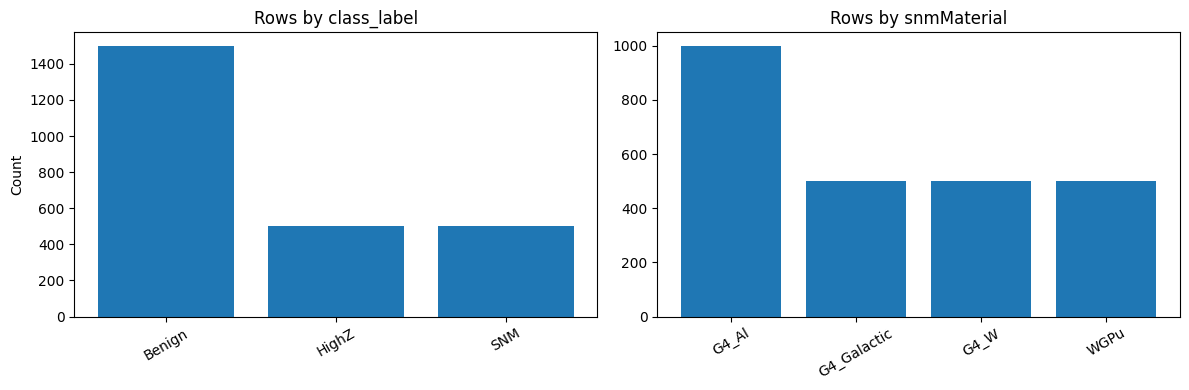

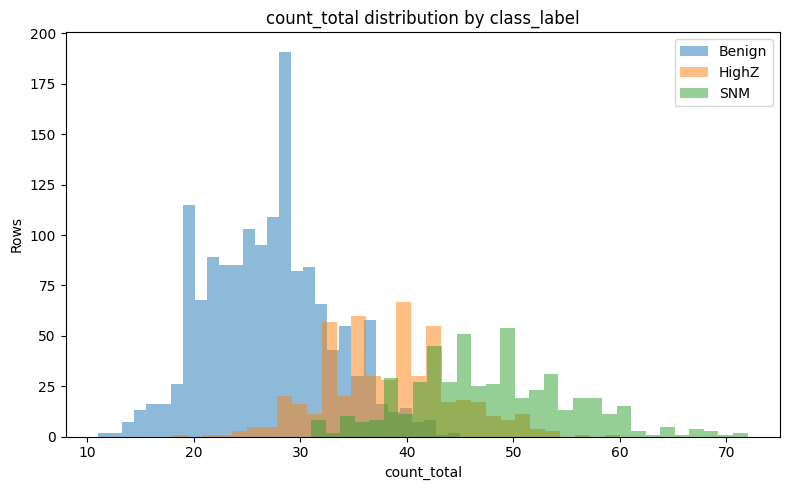

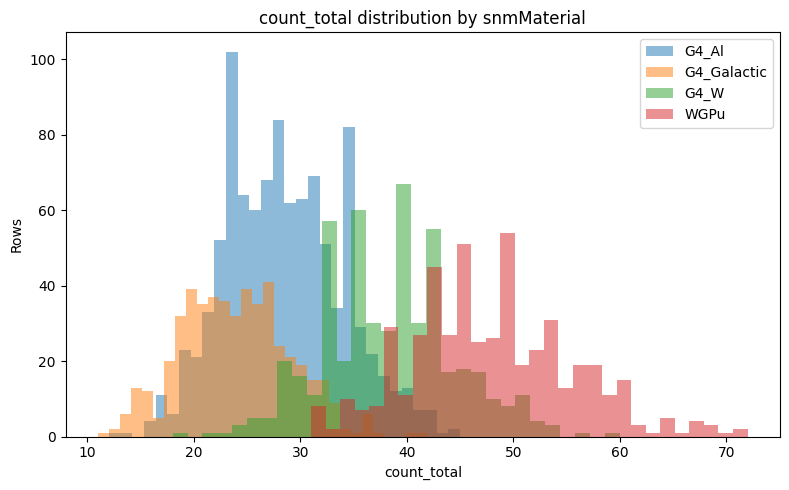

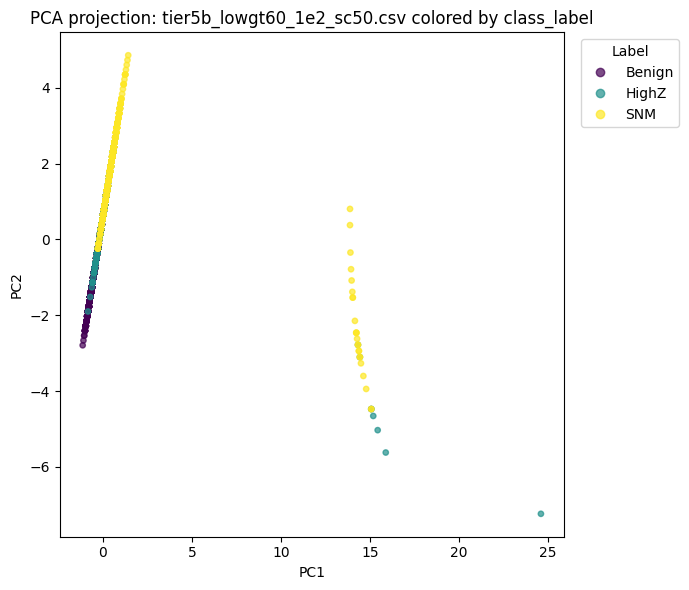

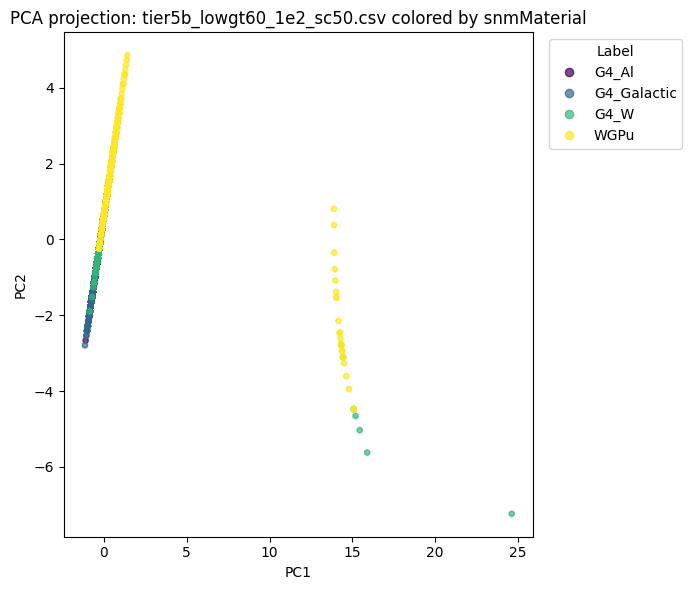

In [34]:

plot_label_counts(df)
plot_total_count_by_label(df, "class_label")
plot_total_count_by_label(df, "snmMaterial")

plot_pca_projection(X, df["class_label"], f"PCA projection: {active_path.name} colored by class_label")
plot_pca_projection(X, df["snmMaterial"], f"PCA projection: {active_path.name} colored by snmMaterial")


## 4) Unsupervised clustering

Key change relative to the original notebook:

- report **AMI / ARI / NMI** instead of relying on raw accuracy alone
- also report a **Hungarian-matched cluster accuracy** so you still get an intuitive percentage
- use **scaled features** for clustering


### Clustering results against `class_label`

,model,n_clusters,AMI,ARI,NMI,cluster_accuracy_hungarian,silhouette
2,GaussianMixture,3,0.4125,0.5426,0.4131,0.7496,0.6156
0,KMeans,3,0.4027,0.5256,0.4033,0.7384,0.6130
1,Agglomerative,3,0.3775,0.4617,0.3781,0.7084,0.5964


Best clustering model for class_label by AMI: GaussianMixture


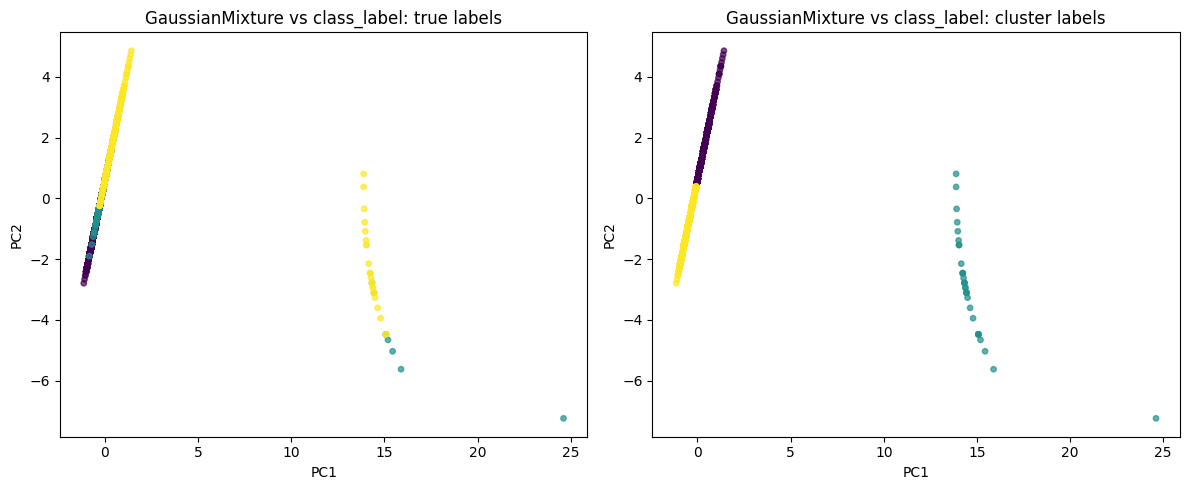

#### Best-model contingency table (`class_label` vs cluster id)

cluster_id,0,1,2
true_label,,,
Benign,83,0,1417
HighZ,294,8,198
SNM,449,24,27


### Clustering results against `snmMaterial`

,model,n_clusters,AMI,ARI,NMI,cluster_accuracy_hungarian,silhouette
2,GaussianMixture,4,0.3534,0.2816,0.3544,0.5320,0.5412
0,KMeans,4,0.3509,0.2602,0.3519,0.5176,0.5515
1,Agglomerative,4,0.3464,0.2790,0.3475,0.5520,0.5711


Best clustering model for snmMaterial by AMI: GaussianMixture


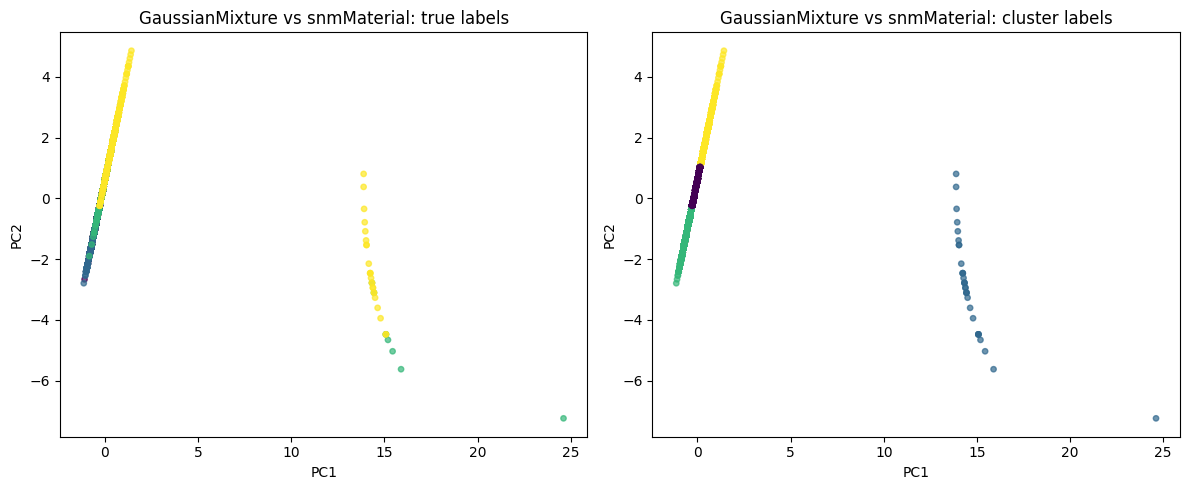

#### Best-model contingency table (`snmMaterial` vs cluster id)

cluster_id,0,1,2,3
true_label,,,,
G4_Al,335,0,655,10
G4_Galactic,50,0,449,1
G4_W,298,8,52,142
WGPu,99,24,0,377


In [35]:

unsup_results_class, unsup_labels_class = run_clustering_suite(X, df["class_label"], random_state=RANDOM_STATE)
display(Markdown("### Clustering results against `class_label`"))
display(unsup_results_class.round(4))

best_unsup_class_model = unsup_results_class.iloc[0]["model"]
print(f"Best clustering model for class_label by AMI: {best_unsup_class_model}")

if best_unsup_class_model in unsup_labels_class:
    plot_best_clustering_pca(
        X,
        df["class_label"],
        unsup_labels_class[best_unsup_class_model],
        f"{best_unsup_class_model} vs class_label",
    )
    display(
        Markdown("#### Best-model contingency table (`class_label` vs cluster id)")
    )
    display(
        pd.crosstab(
            pd.Series(df["class_label"], name="true_label"),
            pd.Series(unsup_labels_class[best_unsup_class_model], name="cluster_id"),
        )
    )

unsup_results_material, unsup_labels_material = run_clustering_suite(X, df["snmMaterial"], random_state=RANDOM_STATE)
display(Markdown("### Clustering results against `snmMaterial`"))
display(unsup_results_material.round(4))

best_unsup_material_model = unsup_results_material.iloc[0]["model"]
print(f"Best clustering model for snmMaterial by AMI: {best_unsup_material_model}")

if best_unsup_material_model in unsup_labels_material:
    plot_best_clustering_pca(
        X,
        df["snmMaterial"],
        unsup_labels_material[best_unsup_material_model],
        f"{best_unsup_material_model} vs snmMaterial",
    )
    display(
        Markdown("#### Best-model contingency table (`snmMaterial` vs cluster id)")
    )
    display(
        pd.crosstab(
            pd.Series(df["snmMaterial"], name="true_label"),
            pd.Series(unsup_labels_material[best_unsup_material_model], name="cluster_id"),
        )
    )


## 5) Supervised baselines

This section evaluates a few classical baselines:

- `DummyMostFrequent` as a sanity baseline
- `LogisticRegression`
- `RandomForest`
- `GradientBoosting`

For each target, the notebook reports:

- CV mean and standard deviation
- holdout metrics
- confusion matrix
- classification report
- top features for the best model


### Supervised results for `class_label`

,model,cv_accuracy_mean,cv_accuracy_std,cv_bal_acc_mean,cv_bal_acc_std,cv_f1_macro_mean,cv_f1_macro_std,test_accuracy,test_bal_acc,test_f1_macro
0,LogisticRegression,0.7945,0.0259,0.7019,0.0301,0.7096,0.0305,0.790,0.7011,0.7009
1,RandomForest,0.7805,0.0189,0.6875,0.0248,0.6935,0.0228,0.778,0.6878,0.6862
2,GradientBoosting,0.7785,0.0168,0.6825,0.0183,0.6862,0.0184,0.778,0.6878,0.6862
3,DummyMostFrequent,0.6000,0.0000,0.3333,0.0000,0.2500,0.0000,0.600,0.3333,0.2500


Best class_label model by CV macro-F1: LogisticRegression


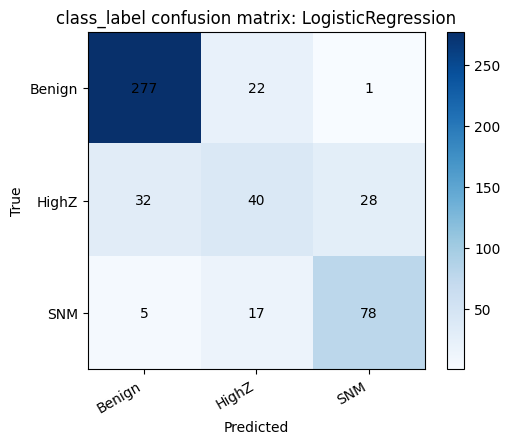

Classification report for class_label:
              precision    recall  f1-score   support

      Benign       0.88      0.92      0.90       300
       HighZ       0.51      0.40      0.45       100
         SNM       0.73      0.78      0.75       100

    accuracy                           0.79       500
   macro avg       0.71      0.70      0.70       500
weighted avg       0.78      0.79      0.78       500



#### Top 10 class_label features

,feature,importance
0,n_clusters,0.963281
1,count_total,0.962752
2,mean_cluster,0.273453
3,max_cluster,0.269910
4,n_clusters_ge2,0.098454


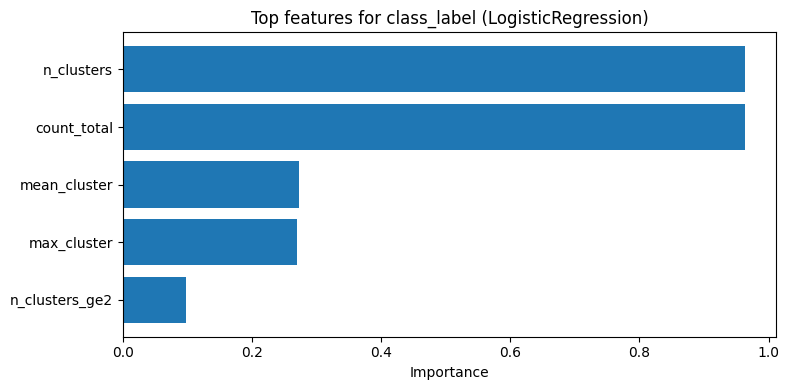

In [36]:

class_results, class_fits = evaluate_supervised_models(
    X,
    df["class_label"],
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE,
    cv_folds=CV_FOLDS,
)

display(Markdown("### Supervised results for `class_label`"))
display(class_results.round(4))

best_class_model_name = class_results.iloc[0]["model"]
best_class_fit = class_fits[best_class_model_name]

print(f"Best class_label model by CV macro-F1: {best_class_model_name}")
plot_confusion_for_fit(best_class_fit, f"class_label confusion matrix: {best_class_model_name}")

class_target_names = best_class_fit["encoder"].inverse_transform(
    np.arange(len(best_class_fit["encoder"].classes_))
)
print("Classification report for class_label:")
print(
    classification_report(
        best_class_fit["y_test"],
        best_class_fit["y_pred"],
        target_names=class_target_names,
    )
)

class_importance = extract_feature_importance(best_class_fit["model"], feature_cols)
if class_importance is None:
    print(f"{best_class_model_name} does not expose native feature importances / coefficients.")
else:
    display(Markdown("#### Top 10 class_label features"))
    display(class_importance.head(10))
    plot_top_features(class_importance, f"Top features for class_label ({best_class_model_name})", top_n=TOP_N_FEATURES)


### Supervised results for `snmMaterial`

,model,cv_accuracy_mean,cv_accuracy_std,cv_bal_acc_mean,cv_bal_acc_std,cv_f1_macro_mean,cv_f1_macro_std,test_accuracy,test_bal_acc,test_f1_macro
0,LogisticRegression,0.6250,0.0119,0.5853,0.0135,0.5933,0.0127,0.608,0.5550,0.5608
1,GradientBoosting,0.6135,0.0111,0.5672,0.0178,0.5738,0.0156,0.604,0.5588,0.5629
2,RandomForest,0.6105,0.0093,0.5638,0.0140,0.5697,0.0115,0.598,0.5450,0.5459
3,DummyMostFrequent,0.4000,0.0000,0.2500,0.0000,0.1429,0.0000,0.400,0.2500,0.1429


Best snmMaterial model by CV macro-F1: LogisticRegression


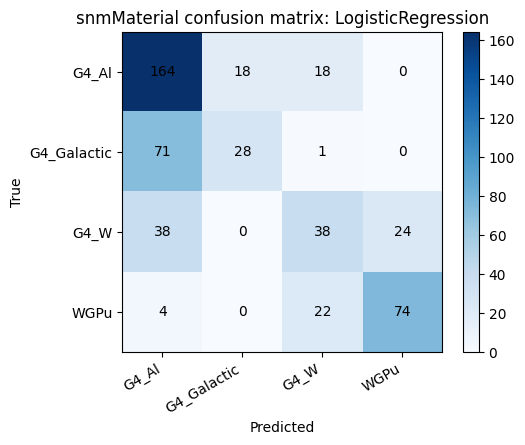

Classification report for snmMaterial:
              precision    recall  f1-score   support

       G4_Al       0.59      0.82      0.69       200
 G4_Galactic       0.61      0.28      0.38       100
        G4_W       0.48      0.38      0.42       100
        WGPu       0.76      0.74      0.75       100

    accuracy                           0.61       500
   macro avg       0.61      0.55      0.56       500
weighted avg       0.61      0.61      0.59       500



#### Top 10 snmMaterial features

,feature,importance
0,n_clusters,1.213628
1,count_total,1.212790
2,mean_cluster,0.230881
3,max_cluster,0.198337
4,n_clusters_ge2,0.093695


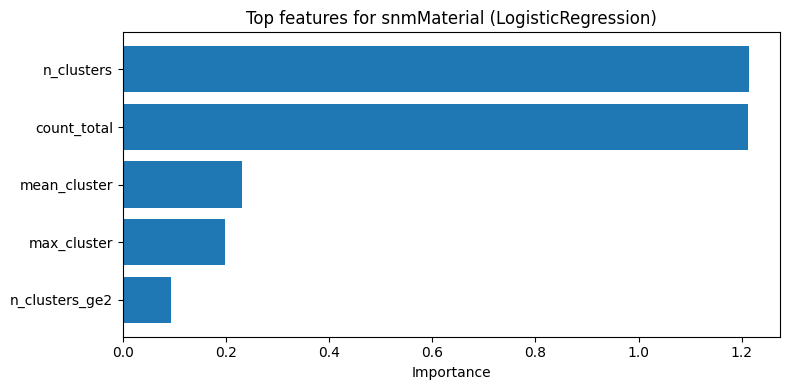

In [37]:

material_results, material_fits = evaluate_supervised_models(
    X,
    df["snmMaterial"],
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE,
    cv_folds=CV_FOLDS,
)

display(Markdown("### Supervised results for `snmMaterial`"))
display(material_results.round(4))

best_material_model_name = material_results.iloc[0]["model"]
best_material_fit = material_fits[best_material_model_name]

print(f"Best snmMaterial model by CV macro-F1: {best_material_model_name}")
plot_confusion_for_fit(best_material_fit, f"snmMaterial confusion matrix: {best_material_model_name}")

material_target_names = best_material_fit["encoder"].inverse_transform(
    np.arange(len(best_material_fit["encoder"].classes_))
)
print("Classification report for snmMaterial:")
print(
    classification_report(
        best_material_fit["y_test"],
        best_material_fit["y_pred"],
        target_names=material_target_names,
    )
)

material_importance = extract_feature_importance(best_material_fit["model"], feature_cols)
if material_importance is None:
    print(f"{best_material_model_name} does not expose native feature importances / coefficients.")
else:
    display(Markdown("#### Top 10 snmMaterial features"))
    display(material_importance.head(10))
    plot_top_features(material_importance, f"Top features for snmMaterial ({best_material_model_name})", top_n=TOP_N_FEATURES)


## 6) Optional hyperparameter search

Set `RUN_HYPERPARAMETER_SEARCH = True` in the config cell to enable this.

The point here is not exhaustive optimization. It is to give you a **reasonable parameter sweep**, print the **best parameter set**, and show the **top 10 candidate configurations**.


In [38]:

if RUN_HYPERPARAMETER_SEARCH:
    print(f"Running hyperparameter search for target={TUNING_TARGET!r}, model={TUNING_MODEL!r}")
    tuning_target = df[TUNING_TARGET]

    search, tuning_encoder, tuning_cv_table = run_random_search(
        X,
        tuning_target,
        model_name=TUNING_MODEL,
        n_iter=N_RANDOM_SEARCH_ITERS,
        random_state=RANDOM_STATE,
        cv_folds=CV_FOLDS,
    )

    print(f"Best balanced_accuracy: {search.best_score_:.4f}")
    print("Best parameters:")
    print(search.best_params_)

    display(Markdown("### Top 10 hyperparameter candidates"))
    display(tuning_cv_table.head(10))
else:
    print("RUN_HYPERPARAMETER_SEARCH is False. Set it to True in the config cell to enable tuning.")


RUN_HYPERPARAMETER_SEARCH is False. Set it to True in the config cell to enable tuning.


## 7) Compare the same baseline across many tier files

This is the piece that is most helpful once the notebook lives in the `ml_datasets` directory.

By default it looks only at files matching `COMPARE_GLOB`, which should usually stay within one `source_case` such as `sc50`. That avoids accidentally mixing different source assumptions into one comparison.


Matched 19 datasets with COMPARE_GLOB='tier*_sc50.csv'
Feature view for broad comparison: 'counts_clusters_only'


,dataset
0,tier0_ideal_ap9avg_sc50.csv
1,tier1_flatbg2hz_ap9avg_sc50.csv
2,tier2_flatbg2hz_selfbg010_ap9avg_sc50.csv
3,tier3_resp035_thr05_smear_ap9avg_sc50.csv
4,tier4a_standoff5m_ap9avg_sc50.csv
5,tier4b_panel0p5m_ap9avg_sc50.csv
6,tier4c_standoff5m_panel0p5m_ap9avg_sc50.csv
7,tier5a_highgt60_1e4_sc50.csv
8,tier5b_lowgt60_1e2_sc50.csv
9,tier6_highgt60_dist_100m_sc50.csv


### RandomForest holdout summary across datasets: class_label

,dataset,tier,source_case,n_rows,n_features,n_energy_features,n_cluster_features,holdout_accuracy,holdout_balanced_accuracy,holdout_f1_macro,dropped_constant_features
0,tier0_ideal_ap9avg_sc50.csv,tier0,50,2500,7,0,6,1.000,1.0000,1.0000,1
1,tier1_flatbg2hz_ap9avg_sc50.csv,tier1,50,2500,7,0,6,1.000,1.0000,1.0000,1
2,tier2_flatbg2hz_selfbg010_ap9avg_sc50.csv,tier2,50,2500,7,0,6,1.000,1.0000,1.0000,1
3,tier3_resp035_thr05_smear_ap9avg_sc50.csv,tier3,50,2500,7,0,6,1.000,1.0000,1.0000,1
4,tier4a_standoff5m_ap9avg_sc50.csv,tier4a,50,2500,6,0,5,1.000,1.0000,1.0000,2
5,tier4b_panel0p5m_ap9avg_sc50.csv,tier4b,50,2500,6,0,5,1.000,1.0000,1.0000,2
6,tier4c_standoff5m_panel0p5m_ap9avg_sc50.csv,tier4c,50,2500,5,0,4,1.000,1.0000,1.0000,3
7,tier5a_highgt60_1e4_sc50.csv,tier5a,50,2500,6,0,5,1.000,1.0000,1.0000,2
8,tier5b_lowgt60_1e2_sc50.csv,tier5b,50,2500,5,0,4,0.778,0.6878,0.6862,3
9,tier6_highgt60_dist_100m_sc50.csv,tier6,50,2500,2,0,1,0.606,0.3633,0.3174,19


### RandomForest holdout summary across datasets: snmMaterial

,dataset,tier,source_case,n_rows,n_features,n_energy_features,n_cluster_features,holdout_accuracy,holdout_balanced_accuracy,holdout_f1_macro,dropped_constant_features
0,tier0_ideal_ap9avg_sc50.csv,tier0,50,2500,7,0,6,1.000,1.0000,1.0000,1
1,tier1_flatbg2hz_ap9avg_sc50.csv,tier1,50,2500,7,0,6,1.000,1.0000,1.0000,1
2,tier2_flatbg2hz_selfbg010_ap9avg_sc50.csv,tier2,50,2500,7,0,6,1.000,1.0000,1.0000,1
3,tier3_resp035_thr05_smear_ap9avg_sc50.csv,tier3,50,2500,7,0,6,1.000,1.0000,1.0000,1
4,tier4a_standoff5m_ap9avg_sc50.csv,tier4a,50,2500,6,0,5,1.000,1.0000,1.0000,2
5,tier4b_panel0p5m_ap9avg_sc50.csv,tier4b,50,2500,6,0,5,0.996,0.9975,0.9963,2
6,tier4c_standoff5m_panel0p5m_ap9avg_sc50.csv,tier4c,50,2500,5,0,4,0.964,0.9650,0.9662,3
7,tier5a_highgt60_1e4_sc50.csv,tier5a,50,2500,6,0,5,1.000,1.0000,1.0000,2
8,tier5b_lowgt60_1e2_sc50.csv,tier5b,50,2500,5,0,4,0.598,0.5450,0.5459,3
9,tier6_highgt60_dist_100m_sc50.csv,tier6,50,2500,2,0,1,0.432,0.3225,0.2664,19


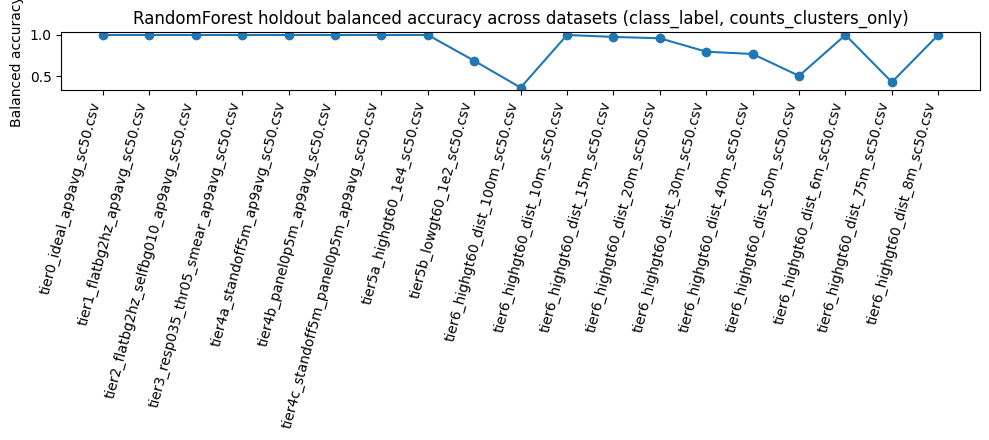

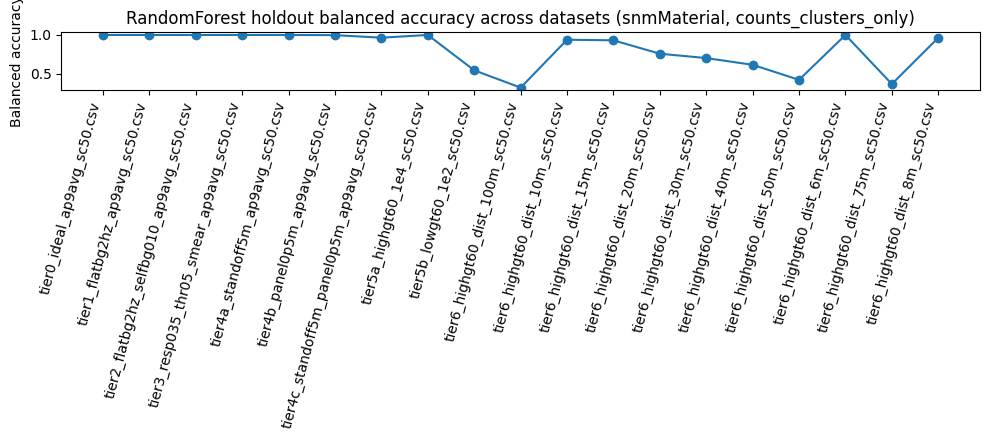

In [39]:
comparison_paths = [
    Path(path)
    for path in available_datasets["path"].tolist()
    if fnmatch.fnmatch(Path(path).name, COMPARE_GLOB)
]

print(f"Matched {len(comparison_paths)} datasets with COMPARE_GLOB={COMPARE_GLOB!r}")
print(f"Feature view for broad comparison: {FEATURE_VIEW!r}")
display(pd.DataFrame({"dataset": [p.name for p in comparison_paths]}))

comparison_class = evaluate_many_datasets(
    comparison_paths,
    target_col="class_label",
    model_name="RandomForest",
    include_measurement_settings=INCLUDE_MEASUREMENT_SETTINGS_AS_FEATURES,
    drop_constant_features=DROP_CONSTANT_FEATURES,
    feature_view=FEATURE_VIEW,
    custom_include_features=CUSTOM_INCLUDE_FEATURES,
    custom_exclude_patterns=CUSTOM_EXCLUDE_PATTERNS,
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE,
)

comparison_material = evaluate_many_datasets(
    comparison_paths,
    target_col="snmMaterial",
    model_name="RandomForest",
    include_measurement_settings=INCLUDE_MEASUREMENT_SETTINGS_AS_FEATURES,
    drop_constant_features=DROP_CONSTANT_FEATURES,
    feature_view=FEATURE_VIEW,
    custom_include_features=CUSTOM_INCLUDE_FEATURES,
    custom_exclude_patterns=CUSTOM_EXCLUDE_PATTERNS,
    random_state=RANDOM_STATE,
    test_size=TEST_SIZE,
)

display(Markdown("### RandomForest holdout summary across datasets: class_label"))
display(comparison_class.round(4))

display(Markdown("### RandomForest holdout summary across datasets: snmMaterial"))
display(comparison_material.round(4))

if not comparison_class.empty:
    plt.figure(figsize=(10, 4.5))
    plt.plot(comparison_class["dataset"], comparison_class["holdout_balanced_accuracy"], marker="o")
    plt.xticks(rotation=75, ha="right")
    plt.ylabel("Balanced accuracy")
    plt.title(f"RandomForest holdout balanced accuracy across datasets (class_label, {FEATURE_VIEW})")
    plt.tight_layout()
    plt.show()

if not comparison_material.empty:
    plt.figure(figsize=(10, 4.5))
    plt.plot(comparison_material["dataset"], comparison_material["holdout_balanced_accuracy"], marker="o")
    plt.xticks(rotation=75, ha="right")
    plt.ylabel("Balanced accuracy")
    plt.title(f"RandomForest holdout balanced accuracy across datasets (snmMaterial, {FEATURE_VIEW})")
    plt.tight_layout()
    plt.show()


## 8) Practical notes for this project

- **Do not mix `sc50`, `sc75`, and `sc95` by accident.** Keep the comparison glob source-case-specific unless you are intentionally testing robustness.
- **Do not train directly on debug columns.** They are excellent for QC and ablation studies, but they can leak scenario truth.
- **If you combine datasets from multiple tiers, be careful with measurement-setting columns.** Settings like `background_rate_hz` or `coinc_ns` may become shortcuts that let the model identify the tier instead of the neutron signature.
- **Use the comparison section to compare tier difficulty, not just one-off accuracy numbers.**

- **Use `FEATURE_VIEW` to stress-test realism.** `counts_clusters_only` is the simplest way to remove explicit energy information and see how much discrimination survives on total counts + coincidence structure alone.
